# Proyek Analisis Data: E-Commerce
- **Nama:** Radithya Danutirta
- **Email:** ds288b6y1465@student.devacademy.id
- **ID Dicoding:** radithya_danutirta_HKkL

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total revenue (BRL) tertinggi dan terendah dari order berstatus *delivered* selama September 2016 – Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue, sebagai dasar penentuan fokus stok dan promosi?

- **Pertanyaan 2:** Berapa selisih rata-rata review score antara order yang terlambat dan yang tepat waktu pada order *delivered* selama September 2016 – Agustus 2018, dan seberapa kuat korelasi durasi pengiriman (`delivery_time`) dengan review score, sebagai dasar penentuan prioritas perbaikan estimasi dan layanan pengiriman?

- **Pertanyaan 3:** Bagaimana segmentasi pelanggan unik berdasarkan RFM (recency, frequency, monetary) pada order *delivered* selama September 2016 – Agustus 2018, dan segmen mana yang menyumbang total spending terbesar, sebagai dasar penentuan target kampanye retensi?

## Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Wrangling

### Gathering Data

#### Memuat seluruh tabel dataset ke dalam DataFrame

Seluruh tabel dibaca dari file CSV dengan `pd.read_csv()` dan disimpan dalam variabel DataFrame masing-masing.

In [4]:
cust_df = pd.read_csv('customers_dataset.csv')
cust_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
geo_df = pd.read_csv('geolocation_dataset.csv')
geo_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [6]:
order_items_df = pd.read_csv('order_items_dataset.csv')
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
order_payments_df = pd.read_csv('order_payments_dataset.csv')
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
orders_df = pd.read_csv('orders_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
products_df = pd.read_csv('products_dataset.csv')
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [11]:
products_cat_name_df = pd.read_csv('product_category_name_translation.csv')
products_cat_name_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [12]:
sellers_df = pd.read_csv('sellers_dataset.csv')
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


**Insight:** (Opsional)
- **Berhasil Memuat Data**: Seluruh 9 tabel dataset e-commerce (customers, orders, order_items, order_payments, order_reviews, products, sellers, geolocation, dan product_category_name_translation) telah berhasil dimuat ke dalam Pandas DataFrame.
- **Gambaran Volume Data**:
  - Dataset transaksi utama (`orders_df`) mencakup 99.441 data pesanan.
  - Dataset detail produk transaksi (`order_items_df`) mencakup 112.650 item.
  - Dataset pelanggan (`cust_df`) mencakup 99.441 baris `customer_id`. Satu `customer_id` mewakili satu order, jadi jumlah pelanggan unik sebenarnya dilihat dari `customer_unique_id`.
  - Dataset ulasan (`order_reviews_df`) mencakup 99.224 ulasan dari pelanggan.
- **Kesiapan Data**: Seluruh DataFrame siap untuk melangkah ke tahap selanjutnya, yaitu **Assessing Data**, untuk mengevaluasi tipe data, *missing values*, dan duplikasi pada masing-masing tabel.

### Assessing Data

#### Identifikasi masalah pada setiap DataFrame

Setiap DataFrame diperiksa menggunakan `info()`, `describe()`, `isnull().sum()`, dan `duplicated().sum()` untuk menemukan masalah seperti missing value, invalid value, duplikat, inaccurate value, inconsistent value, dan outlier.

dataset customer

In [13]:
cust_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [14]:
cust_df.describe(include='all')

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [15]:
cust_df.duplicated().sum()

np.int64(0)

**Insight:**
- Terdapat 99.441 baris dengan `customer_id` unik, tetapi hanya 96.096 `customer_unique_id`. Satu `customer_id` mewakili satu order, sehingga pelanggan yang sama dapat memiliki beberapa `customer_id`.
- Tidak ada missing value dan tidak ada duplikat.

**Steps to Take:**
- Tidak diperlukan pembersihan. Analisis pelanggan (RFM) menggunakan `customer_unique_id`, bukan `customer_id`.

------------------------
dataset geolocation


In [16]:
geo_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [17]:
geo_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


In [18]:
geo_df.isnull().sum()

,0
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [19]:
geo_df.duplicated().sum()

np.int64(261831)

**Insight:**
- Terdapat 261.831 baris duplikat penuh (kode pos, koordinat, kota, dan state identik).

**Steps to Take:**
- Menghapus baris duplikat dengan `drop_duplicates()`.

------------------------
dataset order items

In [20]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [21]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [22]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [23]:
order_items_df.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [24]:
order_items_df.duplicated().sum()

np.int64(0)

**Insight:**
- Kolom `shipping_limit_date` bertipe `object`, padahal berisi tanggal dan waktu.

**Steps to Take:**
- Mengubah `shipping_limit_date` menjadi `datetime` dengan `pd.to_datetime()`.

------------------
dataset order payments

In [25]:
order_payments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [26]:
order_payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [27]:
gagal = order_payments_df[order_payments_df['payment_installments'] == 0]
gagal.merge(orders_df[['order_id', 'order_status']], on='order_id', how='left')

,order_id,payment_sequential,payment_type,payment_installments,payment_value,order_status
0,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69,delivered
1,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94,delivered


In [28]:
order_payments_df.value_counts('payment_type')

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [29]:
order_payments_df.isnull().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [30]:
order_payments_df.duplicated().sum()

np.int64(0)

**Insight:**
- Terdapat 2 baris kartu kredit dengan `payment_installments = 0` (order *delivered*, `payment_sequential = 2`, nilai pembayaran wajar). Cicilan kartu kredit seharusnya minimal 1, sehingga ini dinilai anomali pencatatan.
- Nilai maksimum `payment_sequential` (29), `payment_installments` (24), dan `payment_value` (13.664) tinggi dibanding rata-ratanya, tetapi masih wajar (pembayaran multi-voucher, cicilan panjang, dan order bernilai tinggi).
- `payment_type = not_defined` (3 baris) berasal dari order berstatus *canceled*.

**Steps to Take:**
- Seluruh temuan dibiarkan karena order valid, jumlahnya sangat kecil, dan kolom pembayaran tidak digunakan untuk menjawab pertanyaan bisnis (P1-P3). Order *canceled* tidak ikut analisis karena difilter berstatus *delivered*.

---------------------
dataset order review

In [31]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [32]:
order_reviews_df.describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [33]:
order_reviews_df.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [34]:
order_reviews_df.duplicated().sum()

np.int64(0)

In [35]:
review_more = (order_reviews_df.groupby('order_id')['review_id'].count() > 1).sum()
review_more

np.int64(547)

In [36]:
jumlah_per_order = order_reviews_df['order_id'].value_counts()
print('Order dengan lebih dari 1 review:', (jumlah_per_order > 1).sum())
print('Maksimum review pada satu order:', jumlah_per_order.max())

Order dengan lebih dari 1 review: 547
Maksimum review pada satu order: 3


**Insight:**
- `review_comment_title` dan `review_comment_message` banyak yang kosong. Hal ini wajar karena tidak semua pelanggan menulis komentar.
- Terdapat 547 `order_id` yang memiliki lebih dari satu review.
- Kolom `review_creation_date` dan `review_answer_timestamp` bertipe `object`.

**Steps to Take:**
- Missing value pada komentar dibiarkan karena kolom tersebut tidak digunakan dalam analisis.
- Review ganda diringkas menjadi satu baris per `order_id` dengan merata-ratakan `review_score`, agar tidak menggandakan baris saat digabung.
- Mengubah kedua kolom tanggal menjadi `datetime`.

----------------------
dataset order

In [37]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [38]:
orders_df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [39]:
orders_df.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [40]:
orders_df['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [41]:
orders_df[orders_df['order_delivered_customer_date'].isnull()].value_counts('order_status')

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [42]:
orders_df[(orders_df['order_delivered_carrier_date'].isnull()) & (orders_df['order_status'] == 'delivered')]


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47,2017-11-14 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00


In [43]:
orders_df[(orders_df['order_approved_at'].isnull()) & (orders_df['order_status'] == 'delivered')]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaN,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16 00:00:00
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaN,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20 00:00:00


In [44]:
orders_df[(orders_df['order_delivered_customer_date'].notna()) & (orders_df['order_status'] != 'delivered')]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00


In [45]:
orders_df.duplicated().sum()

np.int64(0)

In [46]:
orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


**Insight:**
- Kolom tanggal bertipe `object`.
- Terdapat 8 order berstatus *delivered* tanpa `order_delivered_customer_date`. Data ini tidak konsisten dan membuat `delivery_time` serta `is_late` tidak dapat dihitung.
- Terdapat 6 order berstatus *canceled* yang `order_delivered_customer_date`-nya terisi. Kemungkinan order dibatalkan setelah barang sampai.
- Missing value pada order dengan status lain (mis. *shipped*, *canceled*) wajar karena barang belum sampai.

**Steps to Take:**
- Mengubah kolom tanggal menjadi `datetime`.
- Menghapus 8 order *delivered* tanpa tanggal sampai (0,008% dari order *delivered*).
- 6 order *canceled* dibiarkan karena analisis hanya memakai order *delivered*. Missing value lainnya dibiarkan karena wajar.

--------------------------
dataset product

In [47]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [48]:
products_df.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [49]:
products_df.duplicated().sum()

np.int64(0)

In [50]:
products_df[products_df['product_weight_g'] == 0]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [51]:
products_df['product_category_name'].value_counts()

,count
product_category_name,
cama_mesa_banho,3029
esporte_lazer,2867
moveis_decoracao,2657
beleza_saude,2444
utilidades_domesticas,2335
...,...
fashion_roupa_infanto_juvenil,5
casa_conforto_2,5
pc_gamer,3


In [52]:
products_df.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [53]:
col = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
produk_miss = products_df[products_df[col].isna().all(axis=1)]
produk_miss

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:
gabungan = produk_miss.merge(order_items_df[['order_id', 'product_id']], on='product_id', how='left')
gabungan

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,order_id
0,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN,85f8ad45e067abd694b627859fa57453
1,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,101157d4fae1c9fb74a00a5dee265c25
2,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1521c6bb7b1028154c8c67cf80fa809f
3,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,415cfaaaa8cea49f934470548797fed1
4,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,415cfaaaa8cea49f934470548797fed1
5,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,595316a07cd3dea9db7adfcc7e247ae7
6,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6e150190fbe04c642a9cf0b80d83ee16
7,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6f497c40431d5fb0cfbd6c943dd29215
8,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,a2456e7f02197951664897a94c87242d
9,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,a7a43f469c0d7bdb0a23a82db125aefa


In [55]:
products_df.duplicated().sum()

np.int64(0)

**Insight:**
- Terdapat 610 produk dengan `product_category_name`, `product_name_lenght`, `product_description_lenght`, dan `product_photos_qty` kosong, serta 2 produk dengan berat dan dimensi kosong (tercatat pada 18 item transaksi di 16 order).
- Terdapat 4 produk dengan `product_weight_g = 0`.

**Steps to Take:**
- `product_category_name` yang kosong diisi "unknown" agar transaksinya tetap masuk analisis revenue per kategori (P1).
- Kolom nama, deskripsi, foto, berat, dan dimensi yang kosong, serta berat 0, dibiarkan karena tidak digunakan dalam analisis.

-------------------------
dataset product category

In [56]:
products_cat_name_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [57]:
products_cat_name_df.describe()

,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


hanya terdapat 71 kategori, sedangkan pada dataset products_df ada 73 kategori

In [58]:
products_cat_name_df.isnull().sum()

,0
product_category_name,0
product_category_name_english,0


In [59]:
products_cat_name_df.duplicated().sum()

np.int64(0)

In [60]:
tanpa_terjemahan = set(products_df['product_category_name'].dropna()) - set(products_cat_name_df['product_category_name'])
print(f'jadi : {tanpa_terjemahan}')

terdampak = order_items_df.merge(
    products_df[products_df['product_category_name'].isin(tanpa_terjemahan)][['product_id']], on='product_id')
print(len(terdampak), terdampak['order_id'].nunique())

jadi : {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
24 22


**Insight:**
- Tabel bersih: 71 baris, tanpa missing value dan duplikat.
- `products_df` memiliki 73 kategori terisi. Dua kategori (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) tidak memiliki terjemahan dan tercatat pada 24 item transaksi (22 order). Kategori "unknown" juga tidak ada di tabel ini.

**Steps to Take:**
- Setelah digabung dengan `products_df`, semua kategori tanpa terjemahan (dua kategori di atas dan "unknown") diisi dengan nama aslinya agar transaksinya tidak hilang dari revenue per kategori (P1).

---------------
dataset seller

In [61]:
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [62]:
sellers_df.describe()

,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000


In [63]:
sellers_df.isnull().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [64]:
sellers_df.duplicated().sum()

np.int64(0)

**Insight:**
- 3.095 penjual, tanpa missing value dan tanpa duplikat, dengan tipe data sesuai.

**Steps to Take:**
- Tidak diperlukan pembersihan.

## Ringkasan Steps to Take

1. **`geo_df`**: Menghapus 261.831 baris duplikat penuh dengan `drop_duplicates()`.
2. **`orders_df`, `order_items_df`, `order_reviews_df`**: Mengubah kolom tanggal dari `object` menjadi `datetime` dengan `pd.to_datetime()`.
3. **`orders_df`**: Menghapus 8 order berstatus *delivered* yang `order_delivered_customer_date`-nya kosong, karena data tidak konsisten dan `delivery_time` serta `is_late` tidak dapat dihitung.
4. **`orders_df`**: Membiarkan 6 order berstatus *canceled* yang tanggal sampainya terisi, karena analisis hanya memakai order *delivered*. Missing value pada order dengan status lain juga dibiarkan karena wajar (barang belum sampai).
5. **`products_df`**: Mengisi 610 `product_category_name` yang kosong dengan "unknown" agar transaksinya tetap masuk analisis revenue per kategori (P1).
6. **`products_df`**: Membiarkan kolom nama, deskripsi, foto, berat, dan dimensi yang kosong, serta `product_weight_g = 0`, karena tidak digunakan dalam analisis.
7. **`products_cat_name_df`**: Setelah digabung dengan `products_df`, mengisi kategori tanpa terjemahan (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`, dan "unknown") dengan nama aslinya agar tidak hilang dari revenue per kategori (P1).
8. **`order_reviews_df`**: Meringkas review ganda menjadi satu baris per `order_id` dengan merata-ratakan `review_score`, agar tidak menggandakan baris saat digabung.
9. **`order_payments_df`**: Membiarkan 2 baris `payment_installments = 0` karena order valid, jumlahnya sangat kecil, dan kolom pembayaran tidak digunakan dalam analisis.
10. **`customers_df` dan `sellers_df`**: Tidak ada masalah, sehingga tidak diperlukan pembersihan.

**Insight:**
- **Kualitas data secara umum baik.** `customers_df`, `order_payments_df`, dan `sellers_df` tidak memiliki missing value maupun duplikat yang bermasalah. `sellers_df` sepenuhnya bersih.
- **Satu `customer_id` mewakili satu order.** Terdapat 99.441 `customer_id` tetapi hanya 96.096 `customer_unique_id`, sehingga analisis pelanggan harus memakai `customer_unique_id`.
- **Tipe data tanggal tidak sesuai.** Kolom tanggal di `orders_df`, `order_items_df`, dan `order_reviews_df` bertipe `object`, padahal berisi tanggal dan waktu.
- **Duplikat pada `geo_df`.** Terdapat 261.831 baris duplikat penuh (kode pos, koordinat, kota, dan state identik).
- **Missing value pada `orders_df`.** Sebagian besar wajar karena order belum dikirim atau dibatalkan. Anomali yang ditemukan: 8 order *delivered* tanpa tanggal sampai, dan 6 order *canceled* yang tanggal sampainya terisi.
- **Missing value pada `products_df`.** Terdapat 610 produk dengan kategori, nama, deskripsi, dan jumlah foto kosong, serta 2 produk dengan berat dan dimensi kosong (tercatat pada 18 item transaksi).
- **Kategori tanpa terjemahan.** `products_df` memiliki 73 kategori sedangkan tabel terjemahan hanya 71. Dua kategori tanpa terjemahan tercatat pada 24 item transaksi (22 order), dan kategori kosong (610 produk) juga tidak memiliki padanan.
- **Review ganda per order.** Terdapat [N] `order_id` yang memiliki lebih dari satu review.
- **Nilai ekstrem pada pembayaran.** `payment_sequential` (maks. 29), `payment_installments` (maks. 24), dan `payment_value` (maks. 13.664) tinggi dibanding rata-ratanya tetapi masih wajar. Anomali kecil: 2 baris kartu kredit dengan `payment_installments = 0`.

### Cleaning Data

#### Memperbaiki masalah yang ditemukan pada tahap assessing

dataset geolocation

In [65]:
geo_df = geo_df.drop_duplicates()
geo_df.duplicated().sum()

np.int64(0)

In [66]:
geo_df.reset_index(drop=True, inplace=True)
geo_df

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP
...,...,...,...,...,...
738327,99965,-28.180655,-52.034367,agua santa,RS
738328,99950,-28.072188,-52.011272,tapejara,RS
738329,99950,-28.068864,-52.012964,tapejara,RS
738330,99950,-28.068639,-52.010705,tapejara,RS


---------------
dataset order

In [67]:
column = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
orders_df[column] = orders_df[column].apply(pd.to_datetime)
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [68]:
drop_on_not_delivered = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
].index

orders_df = orders_df.drop(index=drop_on_not_delivered)

In [69]:
orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


------------------------
dataset order item

In [70]:
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


------------------
dataset order review

In [71]:
col = ['review_creation_date', 'review_answer_timestamp']
order_reviews_df[col] = order_reviews_df[col].apply(pd.to_datetime)
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  object        
 1   order_id                 99224 non-null  object        
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  object        
 4   review_comment_message   40977 non-null  object        
 5   review_creation_date     99224 non-null  datetime64[ns]
 6   review_answer_timestamp  99224 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 5.3+ MB


In [72]:
order_reviews_agg = order_reviews_df.groupby('order_id').agg(
    jumlah_review=('review_score', 'count'),
    review_score=('review_score', 'mean')
).reset_index()
order_reviews_agg

,order_id,jumlah_review,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,1,5.0
1,00018f77f2f0320c557190d7a144bdd3,1,4.0
2,000229ec398224ef6ca0657da4fc703e,1,5.0
3,00024acbcdf0a6daa1e931b038114c75,1,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,5.0
...,...,...,...
98668,fffc94f6ce00a00581880bf54a75a037,1,5.0
98669,fffcd46ef2263f404302a634eb57f7eb,1,5.0
98670,fffce4705a9662cd70adb13d4a31832d,1,5.0
98671,fffe18544ffabc95dfada21779c9644f,1,5.0


8. **`order_reviews_df`**: Meringkas review ganda menjadi satu baris per `order_id` dengan merata-ratakan `review_score`, agar tidak menggandakan baris saat digabung.
9. **`order_payments_df`**: Membiarkan 2 baris `payment_installments = 0` karena order valid, jumlahnya sangat kecil, dan kolom pembayaran tidak digunakan dalam analisis.
10. **`customers_df` dan `sellers_df`**: Tidak ada masalah, sehingga tidak diperlukan pembersihan.

--------------------
dataset product

In [73]:
products_df['product_category_name'].isna().sum()

np.int64(610)

In [74]:
# transaksi di order_items_df yang pakai 610 produk anomali ini
missing_products = products_df[products_df['product_category_name'].isna()]['product_id']
affected_orders = order_items_df[order_items_df['product_id'].isin(missing_products)]
print(f"Jumlah item transaksi terdampak: {len(affected_orders)}")

Jumlah item transaksi terdampak: 1603


In [75]:
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')
products_df[products_df['product_category_name'].isna()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm


--------------------------
dataset product category name translation

In [76]:
set(products_df['product_category_name'].dropna()) - set(products_cat_name_df['product_category_name'])

{'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'}

In [77]:
kolom_nan = pd.DataFrame({
    'product_category_name' : ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'],
    'product_category_name_english' : ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown']
})
products_cat_name_df = pd.concat([products_cat_name_df, kolom_nan], ignore_index=True)

In [78]:
products_cat_name_df['product_category_name'].value_counts()

,count
product_category_name,
beleza_saude,1
informatica_acessorios,1
automotivo,1
cama_mesa_banho,1
moveis_decoracao,1
...,...
fashion_roupa_infanto_juvenil,1
seguros_e_servicos,1
pc_gamer,1


## Exploratory Data Analysis (EDA)

### Explore dataSebelum menjawab pertanyaan bisnis, data hasil pembersihan diverifikasi terlebih dahulu, lalu tabel-tabel digabung menjadi `master_df` dan difilter ke order berstatus *delivered* untuk menghasilkan `master_delivered` serta `order_level`.

In [79]:
# Verifikasi hasil pembersihan data sebelum masuk ke tahap EDA
print("=== VERIFIKASI DATA PASCA CLEANING ===\n")

# 1. Cek Duplikat Geolocation
print(f"Duplikat pada geo_df: {geo_df.duplicated().sum()}")

# 2. Cek tipe data temporal pada orders_df
print("\nTipe data tanggal pada orders_df:")
print(orders_df[['order_purchase_timestamp', 'order_approved_at', 'order_delivered_customer_date']].dtypes)

# 3. Cek missing values pada kategori produk setelah di-imputasi
print(f"\nMissing values kategori di products_df: {products_df['product_category_name'].isnull().sum()}")
print(f"Jumlah produk dengan kategori 'unknown': {len(products_df[products_df['product_category_name'] == 'unknown'])}")

# 4. Tampilkan informasi dasar orders_df yang siap digunakan
print("\nDimensi orders_df sekarang:", orders_df.shape)

# 5. Cek Total Baris Product Translation
print(f"\n{products_cat_name_df['product_category_name'].nunique()}")

=== VERIFIKASI DATA PASCA CLEANING ===

Duplikat pada geo_df: 0

Tipe data tanggal pada orders_df:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_customer_date    datetime64[ns]
dtype: object

Missing values kategori di products_df: 0
Jumlah produk dengan kategori 'unknown': 610

Dimensi orders_df sekarang: (99433, 8)

74


In [80]:
orders_eda = orders_df.copy()

In [81]:
orders_eda['delivery_time'] = (orders_eda['order_delivered_customer_date'] - orders_eda['order_purchase_timestamp']).dt.days
orders_eda['approve_time'] = (orders_eda['order_approved_at'] - orders_eda['order_purchase_timestamp']).dt.days

orders_eda['is_late'] = np.where(
    orders_eda['order_delivered_customer_date'].isna(),
    np.nan,
    orders_eda['order_delivered_customer_date'] > orders_eda['order_estimated_delivery_date']
)
orders_eda['is_late'] = orders_eda['is_late'].astype('boolean')

In [82]:
print('delivery_time negatif:', (orders_eda['delivery_time'] < 0).sum())
print('approve_time negatif:', (orders_eda['approve_time'] < 0).sum())
orders_eda[orders_eda['order_status'] == 'delivered'][['delivery_time', 'approve_time']].describe()

delivery_time negatif: 0
approve_time negatif: 0


,delivery_time,approve_time
count,96470.000000,96456.000000
mean,12.093604,0.264359
std,9.551380,0.729952
min,0.000000,0.000000
25%,6.000000,0.000000
50%,10.000000,0.000000
75%,15.000000,0.000000
max,209.000000,30.000000


Menggabungkan Tabel

Tabel digabung secara bertahap. Setiap merge dicek jumlah barisnya agar tidak ada duplikasi yang menggandakan revenue:
- `orders` + `order_items` lewat `order_id` (satu order bisa punya beberapa item, jadi jumlah baris boleh bertambah di langkah ini).
- + `order_reviews_agg` lewat `order_id` (satu baris per order, jumlah baris harus tetap).
- + `customers` lewat `customer_id` (jumlah baris harus tetap).
- + `products_full` lewat `product_id` (jumlah baris harus tetap).

In [83]:
produk_kategori = pd.merge(
    products_df[['product_id', 'product_category_name']],
    products_cat_name_df,
    on='product_category_name', how='left'
)
print('Produk tanpa terjemahan kategori:', produk_kategori['product_category_name_english'].isna().sum())
print('Jumlah produk:', len(produk_kategori), '| product_id unik:', produk_kategori['product_id'].is_unique)

Produk tanpa terjemahan kategori: 0
Jumlah produk: 32951 | product_id unik: True


In [84]:
master_df = pd.merge(orders_eda, order_items_df, on='order_id', how='left')
master_df = pd.merge(master_df, order_reviews_agg, on='order_id', how='left')
master_df = pd.merge(master_df, cust_df[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='left')
master_df = pd.merge(master_df, produk_kategori[['product_id', 'product_category_name_english']], on='product_id', how='left')

In [85]:
master_delivered = master_df[master_df['order_status'] == 'delivered'].copy()

order_level = pd.merge(
    orders_eda[orders_eda['order_status'] == 'delivered'],
    order_reviews_agg, on='order_id', how='left'
)
print('total_order', master_delivered['order_id'].count())
print('order delivered tanpa review:', order_level['review_score'].isna().sum())
print('Periode:', master_delivered['order_purchase_timestamp'].min(), 's.d.', master_delivered['order_purchase_timestamp'].max())

total_order 110189
order delivered tanpa review: 646
Periode: 2016-09-15 12:16:38 s.d. 2018-08-29 15:00:37


In [86]:
#gambaran umum dari status order, pelanggan, dan review
status = orders_df['order_status'].value_counts()
pd.DataFrame({'jumlah': status, 'persen': (status / status.sum() * 100).round(2)})

,jumlah,persen
order_status,,
delivered,96470,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [87]:
print('customer_id:', cust_df['customer_id'].nunique())
print('customer_unique_id:', cust_df['customer_unique_id'].nunique())

customer_id: 99441
customer_unique_id: 96096


In [88]:
review_analysis = order_reviews_df.groupby('review_score')['review_comment_message'].agg(
    total_review='size',
    ada_komentar='count'
)
review_analysis['persen_komentar'] = (review_analysis['ada_komentar'] / review_analysis['total_review'] * 100).round(2)
review_analysis

,total_review,ada_komentar,persen_komentar
review_score,,,
1,11424,8745,76.55
2,3151,2145,68.07
3,8179,3557,43.49
4,19142,5976,31.22
5,57328,20554,35.85


In [89]:
dist = order_level['review_score'].value_counts().sort_index(ascending=False).to_frame('jumlah_order')
dist['persentase'] = (dist['jumlah_order'] / dist['jumlah_order'].sum() * 100).round(3)
dist

,jumlah_order,persentase
review_score,,
5.000000,56697,59.168
4.500000,53,0.055
4.333333,1,0.001
4.000000,18868,19.690
3.500000,23,0.024
3.333333,1,0.001
3.000000,7915,8.260
2.500000,30,0.031
2.000000,2916,3.043


**Insight:**
- Order berstatus *delivered* mencakup 97,02% dari seluruh order.
- Terdapat 99441 `customer_id` tetapi hanya 96096 `customer_unique_id`, sehingga pelanggan yang sama dapat memiliki beberapa `customer_id`.
- Review bintang 1 yang disertai komentar sebesar 76,55%
- Pada order *delivered*, skor 5 mendominasi (59,168%), sedangkan skor 1 sebesar 9,718%. Sekitar 0,12% order memiliki skor pecahan karena review ganda yang dirata-ratakan.

**Pertanyaan 1:** Kategori produk apa yang menghasilkan total revenue (BRL) tertinggi dan terendah dari order berstatus *delivered* selama September 2016 – Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue, sebagai dasar penentuan fokus stok dan promosi?

In [90]:
revenue = master_delivered.groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    total_order=('order_id', 'nunique'),
    total_item=('order_item_id', 'count'),
    avg_price=('price', 'mean')
).sort_values('total_revenue', ascending=False).reset_index()

revenue['kontribusi_pct'] = (revenue['total_revenue'] / revenue['total_revenue'].sum() * 100).round(2)

print('Jumlah kategori:', len(revenue), '| total revenue:', round(revenue['total_revenue'].sum(), 2))
print('\n5 kategori revenue tertinggi:')
display(revenue.head(5))
print('5 kategori revenue terendah:')
display(revenue.tail(5))
print('Kontribusi 5 teratas:', revenue.head(5)['kontribusi_pct'].sum().round(2), '%')
print('\n5 kategori dengan order terbanyak:')
display(revenue.sort_values('total_order', ascending=False).head(5))

Jumlah kategori: 74 | total revenue: 13220248.93

5 kategori revenue tertinggi:


,product_category_name_english,total_revenue,total_order,total_item,avg_price,kontribusi_pct
0,health_beauty,1233131.72,8647,9465,130.283330,9.33
1,watches_gifts,1165898.98,5493,5857,199.060779,8.82
2,bed_bath_table,1023434.76,9272,10953,93.438762,7.74
3,sports_leisure,954673.55,7529,8430,113.247159,7.22
4,computers_accessories,888613.62,6529,7643,116.265029,6.72


5 kategori revenue terendah:


,product_category_name_english,total_revenue,total_order,total_item,avg_price,kontribusi_pct
69,flowers,1110.04,29,33,33.637576,0.01
70,home_comfort_2,760.27,24,30,25.342333,0.01
71,cds_dvds_musicals,730.00,12,14,52.142857,0.01
72,fashion_childrens_clothes,519.95,7,7,74.278571,0.00
73,security_and_services,283.29,2,2,141.645000,0.00


Kontribusi 5 teratas: 39.83 %

5 kategori dengan order terbanyak:


,product_category_name_english,total_revenue,total_order,total_item,avg_price,kontribusi_pct
2,bed_bath_table,1023434.76,9272,10953,93.438762,7.74
0,health_beauty,1233131.72,8647,9465,130.283330,9.33
3,sports_leisure,954673.55,7529,8430,113.247159,7.22
4,computers_accessories,888613.62,6529,7643,116.265029,6.72
5,furniture_decor,711927.69,6307,8160,87.246040,5.39


**Insight:**
- 5 kategori revenue tertinggi adalah health_beauty (BRL 1.233.131,72), watches_gifts (BRL 1.165.898,98), bed_bath_table (BRL 1.023.434,76), sports_leisure (BRL 954.673,55), dan computers_accessories (BRL 888.613,62), dengan total BRL 5.265.752,63 atau 39,83% dari seluruh revenue order delivered.
- 5 kategori revenue terendah adalah flowers (BRL 1.110,04), home_comfort_2 (BRL 760,27), cds_dvds_musicals (BRL 730,00), fashion_childrens_clothes (BRL 519,95), dan security_and_services (BRL 283,29), masing-masing di bawah BRL 1.200 (atau di bawah BRL 1.111).
- Peringkat revenue tidak selalu sama dengan peringkat volume: bed_bath_table memiliki order terbanyak (9.272 order) dengan harga rata-rata BRL 93,44, sedangkan health_beauty dan watches_gifts unggul di posisi 1 dan 2 revenue karena harga rata-ratanya jauh lebih tinggi, masing-masing BRL 130,28 dan BRL 199,06.

**Pertanyaan 2:** Berapa selisih rata-rata review score antara order yang terlambat dan yang tepat waktu pada order *delivered* selama September 2016 – Agustus 2018, dan seberapa kuat korelasi durasi pengiriman (`delivery_time`) dengan review score, sebagai dasar penentuan prioritas perbaikan estimasi dan layanan pengiriman?

In [91]:
print('Order terlambat:', round(order_level['is_late'].astype(float).mean() * 100, 1), '%')

delivery_review = order_level.groupby('is_late').agg(
    jumlah_order=('order_id', 'count'),
    rata_rata_rating=('review_score', 'mean'),
    median_rating=('review_score', 'median'),
    avg_delivery_time=('delivery_time', 'mean')
).reset_index()
display(delivery_review)

rating = order_level.groupby('is_late')['review_score'].mean()
print('Selisih rating (tepat waktu - terlambat):', round(rating.loc[False] - rating.loc[True], 2))
print('Korelasi delivery_time vs review_score  :', round(order_level['delivery_time'].corr(order_level['review_score']), 2))

Order terlambat: 8.1 %


,is_late,jumlah_order,rata_rata_rating,median_rating,avg_delivery_time
0,False,88644,4.294292,5.0,10.419329
1,True,7826,2.566506,2.0,31.057884


Selisih rating (tepat waktu - terlambat): 1.73
Korelasi delivery_time vs review_score  : -0.33


In [92]:
order_level['kelompok_durasi'] = pd.cut(
    order_level['delivery_time'], [-1, 7, 14, 21, 30, 200],
    labels=['<=7 hari', '8-14 hari', '15-21 hari', '22-30 hari', '>30 hari']
)
order_level.groupby('kelompok_durasi', observed=True)['review_score'].agg(
    jumlah_order='count', rata_rata_rating='mean'
)

,jumlah_order,rata_rata_rating
kelompok_durasi,,
<=7 hari,33539,4.408669
8-14 hari,36190,4.289154
15-21 hari,15264,4.102332
22-30 hari,6824,3.493235
>30 hari,4006,2.175487


**Insight:**
- 8.1% order *delivered* terlambat dari estimasi.
- Rata-rata review score order terlambat 2.56 dibanding 4.29 pada order tepat waktu (selisih 1.73 poin). Rata-rata durasi pengiriman 31 hari vs 10 hari.
- Korelasi `delivery_time` dengan `review_score` sebesar -0.33 (arah negatif, tergolong negatif lemah).
- Rata-rata rating cenderung menurun seiring bertambahnya durasi: <=7 hari (4,41), 8–14 hari (4,29), 15–21 hari (4,10), 22–30 hari (3,49), hingga anjlok tajam di >30 hari (2,18).
- Catatan: ini analisis hubungan agregasi dan korelasi, keterlambatan dan durasi pengiriman juga saling berkaitan.

**Pertanyaan 3:** Bagaimana segmentasi pelanggan unik berdasarkan RFM (recency, frequency, monetary) pada order *delivered* selama September 2016 – Agustus 2018, dan segmen mana yang menyumbang total spending terbesar, sebagai dasar penentuan target kampanye retensi?

In [93]:
rfm_df = master_delivered.groupby('customer_unique_id').agg(
    max_order_timestamp=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum')
).reset_index()

recent_date = rfm_df['max_order_timestamp'].max() + pd.Timedelta(days=1)
rfm_df['recency'] = (recent_date - rfm_df['max_order_timestamp']).dt.days

print('Jumlah pelanggan unik:', len(rfm_df))
rfm_df[['recency', 'frequency', 'monetary']].describe()

Jumlah pelanggan unik: 93350


,recency,frequency,monetary
count,93350.000000,93350.000000,93350.000000
mean,237.950070,1.033423,141.620235
std,152.589932,0.209106,215.702028
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.700000
75%,346.000000,1.000000,154.697500
max,714.000000,15.000000,13440.000000


In [94]:
rfm_df['r_score'] = pd.qcut(rfm_df['recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm_df['f_score'] = np.where(rfm_df['frequency'] >= 2, 2, 1)   # mayoritas pelanggan hanya 1x belanja, jadi dibagi 2 kelompok

def segment(row):
    if row['f_score'] == 2 and row['r_score'] >= 3:
        return 'Loyal'
    elif row['r_score'] >= 3 and row['m_score'] >= 3:
        return 'Big Spender Baru'
    elif row['r_score'] <= 2 and row['m_score'] >= 3:
        return 'At Risk (Spender Besar)'
    elif row['r_score'] <= 2:
        return 'Lost / Dormant'
    return 'Regular'

rfm_df['segment'] = rfm_df.apply(segment, axis=1)

In [95]:
seg = rfm_df.groupby('segment').agg(
    jumlah_pelanggan=('customer_unique_id', 'count'),
    total_spending=('monetary', 'sum')
).sort_values('total_spending', ascending=False).reset_index()

seg['pct_pelanggan'] = (seg['jumlah_pelanggan'] / seg['jumlah_pelanggan'].sum() * 100).round(1)
seg['pct_spending'] = (seg['total_spending'] / seg['total_spending'].sum() * 100).round(1)
display(seg)

print('Pelanggan repeat (>=2 order):', round((rfm_df['frequency'] >= 2).mean() * 100, 1), '%')

,segment,jumlah_pelanggan,total_spending,pct_pelanggan,pct_spending
0,At Risk (Spender Besar),23075,5457724.41,24.7,41.3
1,Big Spender Baru,22289,5163114.36,23.9,39.1
2,Lost / Dormant,23600,1117801.89,25.3,8.5
3,Regular,22842,1073661.20,24.5,8.1
4,Loyal,1544,407947.07,1.7,3.1


Pelanggan repeat (>=2 order): 3.0 %


**Insight:**
- 3% pelanggan unik pernah belanja lebih dari satu kali, sehingga 97% hanya berbelanja satu kali.
- Segmen Lost/Dormant memiliki pelanggan terbanyak (25.3%), sedangkan segmen At Risk menyumbang spending terbesar (41.3% dari total).
- Segmen Loyal hanya 1.7% pelanggan dan 3.1% spending.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Kategori produk apa yang menghasilkan total revenue (BRL) tertinggi dan terendah dari order berstatus *delivered* selama September 2016 – Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue, sebagai dasar penentuan fokus stok dan promosi?

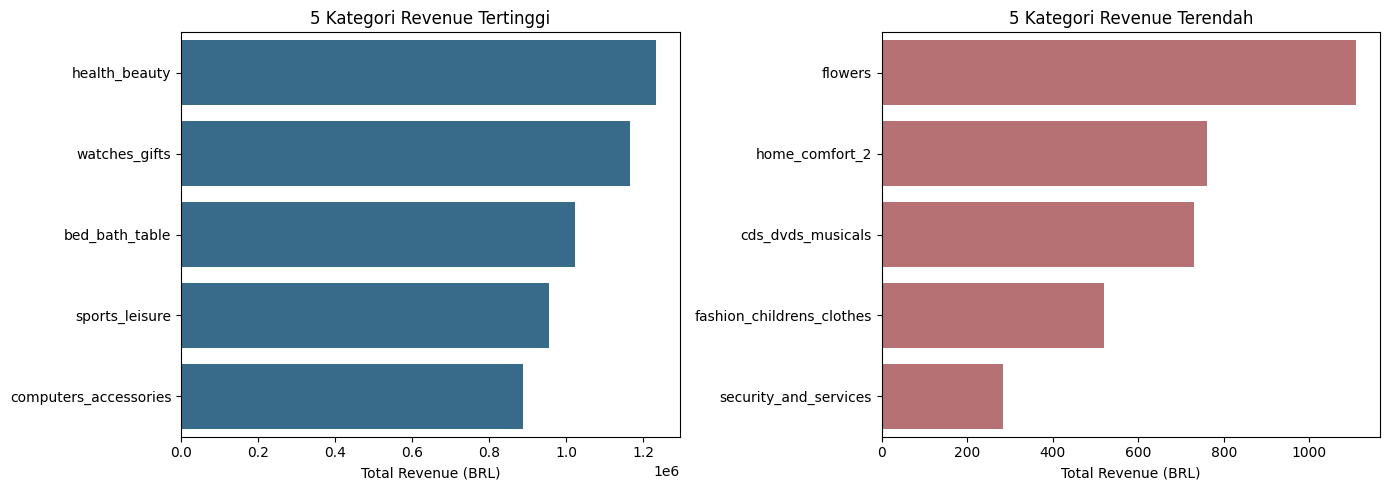

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=revenue.head(5), x='total_revenue', y='product_category_name_english', color='#2a6f97', ax=ax[0])
ax[0].set_title('5 Kategori Revenue Tertinggi')
sns.barplot(data=revenue.tail(5), x='total_revenue', y='product_category_name_english', color='#c1666b', ax=ax[1])
ax[1].set_title('5 Kategori Revenue Terendah')
for a in ax: a.set_xlabel('Total Revenue (BRL)'); a.set_ylabel('')
plt.tight_layout(); plt.show()

**Insight:**
- Health_beauty memiliki revenue tertinggi (BRL 1.233.131,72). Lima kategori teratas menyumbang 39.83% dari total revenue.
- Lima kategori terendah hanya menyumbang BRL 3.403,55 (sekitar 0.03%), dengan security_and_services paling rendah (BRL 283,29).
- Bed_bath_table memiliki order terbanyak (9.272), tetapi watches_gifts berada di posisi kedua revenue karena harga rata-ratanya BRL 199,06.

### Pertanyaan 2:

Berapa selisih rata-rata review score antara order yang terlambat dan yang tepat waktu pada order *delivered* selama September 2016 – Agustus 2018, dan seberapa kuat korelasi durasi pengiriman (`delivery_time`) dengan review score, sebagai dasar penentuan prioritas perbaikan estimasi dan layanan pengiriman?



In [97]:
order_level.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96470 non-null  object        
 1   customer_id                    96470 non-null  object        
 2   order_status                   96470 non-null  object        
 3   order_purchase_timestamp       96470 non-null  datetime64[ns]
 4   order_approved_at              96456 non-null  datetime64[ns]
 5   order_delivered_carrier_date   96469 non-null  datetime64[ns]
 6   order_delivered_customer_date  96470 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96470 non-null  datetime64[ns]
 8   delivery_time                  96470 non-null  float64       
 9   approve_time                   96456 non-null  float64       
 10  is_late                        96470 non-null  boolean       
 11  jumlah_review  

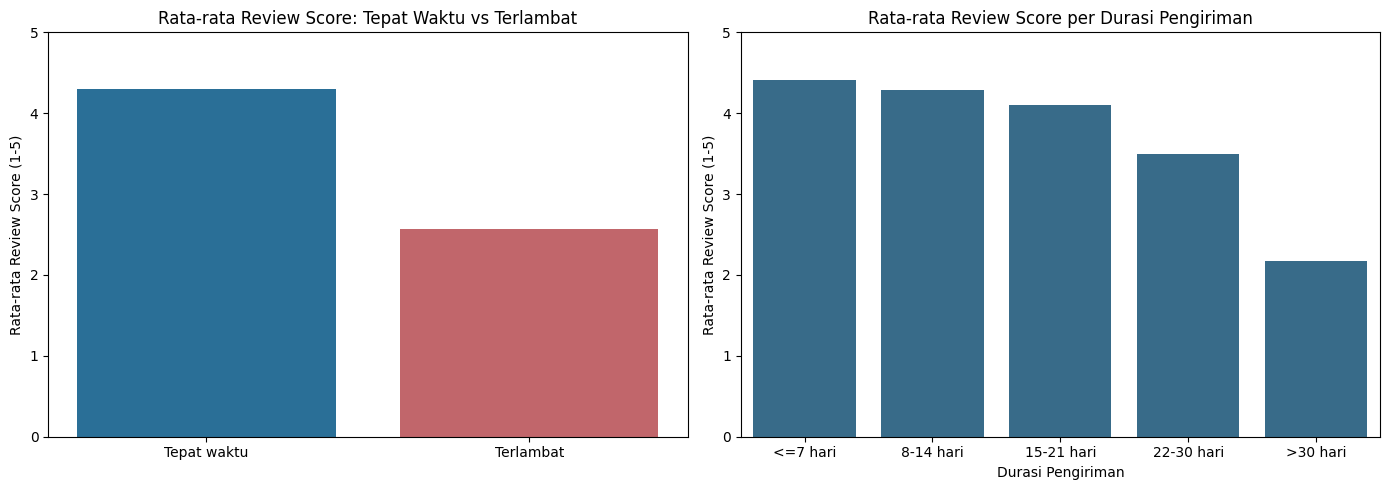

In [98]:
by_dur = order_level.groupby('kelompok_durasi', observed=True)['review_score'].mean().reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(['Tepat waktu', 'Terlambat'], delivery_review['rata_rata_rating'], color=['#2a6f97', '#c1666b'])
ax[0].set_title('Rata-rata Review Score: Tepat Waktu vs Terlambat')
sns.barplot(data=by_dur, x='kelompok_durasi', y='review_score', color='#2a6f97', ax=ax[1])
ax[1].set_title('Rata-rata Review Score per Durasi Pengiriman')
ax[1].set_xlabel('Durasi Pengiriman')
for a in ax: a.set_ylim(0, 5); a.set_ylabel('Rata-rata Review Score (1-5)')
plt.tight_layout(); plt.show()

**Insight:**
- Sebanyak 8.1% order delivered terlambat. Rata-rata review score order terlambat 2.57, jauh di bawah 4.29 pada order tepat waktu (selisih 1.73 poin).
- Rata-rata review score relatif stabil sampai 21 hari (4.41 sampai 4.10), lalu turun menjadi 3.49 pada 22-30 hari dan 2.18 pada lebih dari 30 hari.
- Korelasi `delivery_time` dengan review score sebesar -0.33 (negatif, sedang). Ini hubungan, bukan bukti sebab-akibat.

### pertanyaan 3 :

Bagaimana segmentasi pelanggan unik berdasarkan RFM (recency, frequency, monetary) pada order *delivered* selama September 2016 – Agustus 2018, dan segmen mana yang menyumbang total spending terbesar, sebagai dasar penentuan target kampanye retensi?

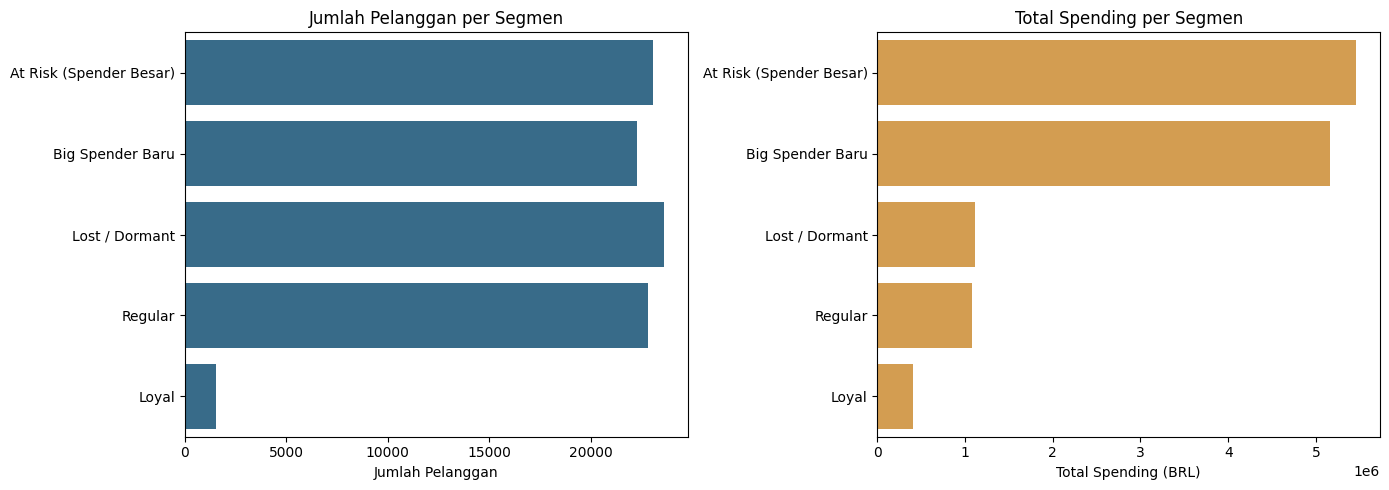

In [99]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=seg, x='jumlah_pelanggan', y='segment', color='#2a6f97', ax=ax[0])
ax[0].set_title('Jumlah Pelanggan per Segmen'); ax[0].set_xlabel('Jumlah Pelanggan')
sns.barplot(data=seg, x='total_spending', y='segment', color='#e9a03b', ax=ax[1])
ax[1].set_title('Total Spending per Segmen'); ax[1].set_xlabel('Total Spending (BRL)')
for a in ax: a.set_ylabel('')
plt.tight_layout(); plt.show()

**Insight:**
- Segmen At Risk (Spender Besar) berisi 24.7% pelanggan tetapi menyumbang 41.3% total spending. Big Spender Baru menyumbang 39.1%. Keduanya bersama-sama sekitar 80% spending.
- Segmen Lost / Dormant dan Regular masing-masing sekitar 25% pelanggan, tetapi hanya menyumbang 8.5% dan 8.1% spending.
- Hanya 3% pelanggan yang berbelanja lebih dari sekali, dan Loyal hanya 1.7% pelanggan (3.1% spending).

## Analisis Lanjutan (Opsional)

Analisis geospasial untuk melihat apakah keterlambatan pengiriman terkonsentrasi di wilayah tertentu. Persentase order terlambat dihitung per state pelanggan, sebagai dasar penentuan wilayah yang diprioritaskan dalam perbaikan layanan pengiriman. State dengan kurang dari 500 order tidak dibandingkan karena persentasenya tidak stabil pada jumlah data yang sedikit.

In [100]:
state_df = pd.merge(order_level[['order_id', 'customer_id', 'is_late', 'review_score']],
                    cust_df[['customer_id', 'customer_state']], on='customer_id', how='left')

state_late = state_df.groupby('customer_state').agg(
    jumlah_order=('order_id', 'count'),
    persen_terlambat=('is_late', lambda x: x.astype(float).mean() * 100),
    rata_rata_rating=('review_score', 'mean')
).reset_index()

state_late = state_late[state_late['jumlah_order'] >= 500].sort_values('persen_terlambat', ascending=False)
state_late.head(10)

,customer_state,jumlah_order,persen_terlambat,rata_rata_rating
9,MA,717,19.665272,3.833567
5,CE,1279,15.324472,3.941870
4,BA,3256,14.035627,3.930009
18,RJ,12350,13.473684,3.965141
13,PA,946,12.367865,3.909968
7,ES,1995,12.230576,4.079736
11,MS,701,11.554922,4.160229
14,PB,517,11.025145,4.076172
15,PE,1593,10.797238,4.082964
23,SC,3546,9.757473,4.133276


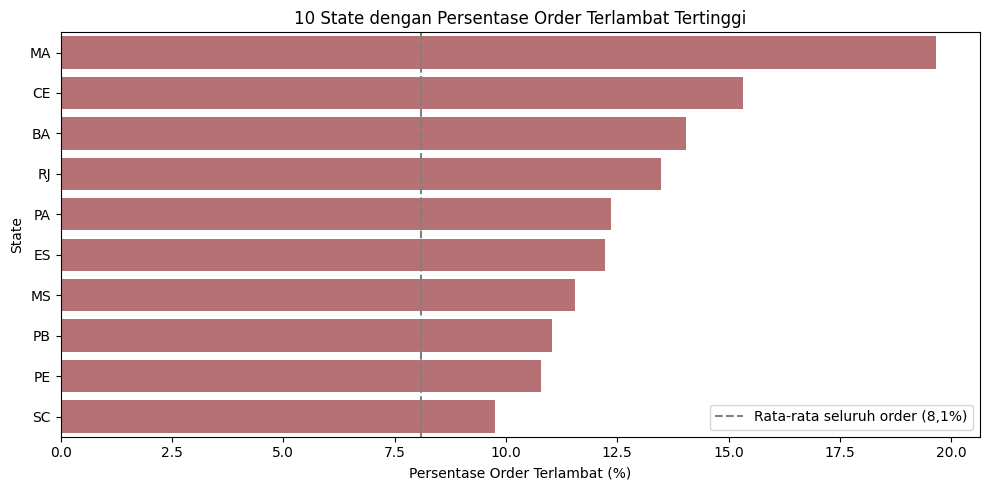

In [101]:
plt.figure(figsize=(10, 5))
sns.barplot(data=state_late.head(10), x='persen_terlambat', y='customer_state', color='#c1666b')
plt.axvline(8.1, color='gray', linestyle='--', label='Rata-rata seluruh order (8,1%)')
plt.title('10 State dengan Persentase Order Terlambat Tertinggi')
plt.xlabel('Persentase Order Terlambat (%)'); plt.ylabel('State')
plt.legend(); plt.tight_layout(); plt.show()

**Insight:**
- State dengan persentase order terlambat tertinggi adalah MA (19.66%), diikuti CE (15.32%), dibandingkan rata-rata seluruh order sebesar 8,1%.
- State dengan jumlah order terbesar, RJ memiliki persentase terlambat 13.47%.
- Rata-rata review score di state dengan keterlambatan tertinggi adalah 3.83

## Conclusion & Recommendation

**Conclusion**
- **Pertanyaan 1:** Health_beauty, watches_gifts, bed_bath_table, sports_leisure, dan computers_accessories adalah 5 kategori dengan revenue tertinggi dan menyumbang 39.83% dari total revenue order delivered. Lima kategori terendah hanya menyumbang BRL 3.403,55 (sekitar 0.03%). Sebagai dasar penentuan fokus stok dan promosi, lima kategori teratas layak diprioritaskan.
- **Pertanyaan 2:** Sebanyak 8.1% order delivered terlambat. Rata-rata review score order terlambat 2.57 dibanding 4.29 pada order tepat waktu (selisih 1.73 poin), dan durasi pengiriman berkorelasi negatif sedang dengan review score (-0.33). Rata-rata review score turun tajam pada pengiriman di atas 21 hari (3.49 pada 22-30 hari dan 2,18 pada lebih dari 30 hari). Sebagai dasar prioritas perbaikan, pengiriman yang melewati sekitar 3 minggu dan akurasi estimasi pengiriman perlu diprioritaskan.
- **Pertanyaan 3:** Sekitar 97% pelanggan unik hanya berbelanja satu kali. Segmen At Risk (Spender Besar) menyumbang spending terbesar (41.3% dari 24.7% pelanggan), diikuti Big Spender Baru (39.1%). Sebagai dasar target kampanye retensi, segmen At Risk menjadi sasaran utama.

**Rekomendasi Action Item**
- Tinjau akurasi estimasi pengiriman dan prioritaskan penanganan pengiriman yang melewati 21 hari, terutama di wilayah dengan persentase keterlambatan tertinggi (MA dan CE), karena rata-rata review score turun tajam pada pengiriman yang lama.
- Jalankan kampanye repeat-order (misalnya voucher) untuk segmen At Risk, karena segmen ini menyimpan 41.3% spending tetapi sudah lama tidak berbelanja.
- Pertahankan stok dan promosi pada 5 kategori teratas yang menyumbang 39.83% revenue.

In [102]:
import os
os.makedirs('dashboard', exist_ok=True)
cols = ['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'delivery_time',
        'is_late', 'review_score', 'price', 'product_category_name_english', 'customer_state']
main_df = master_delivered[cols].dropna(subset=['is_late']).copy()
main_df.to_csv('dashboard/main_data.csv', index=False)
print(main_df.shape)

(110189, 9)


In [103]:
from google.colab import files
files.download('dashboard/main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>